# Spatial distribution of chemical classes on MSI images

This notebook projects METASPACE ion images onto the classes of selected label-graph variants and shows how chemical classes are distributed over the tissue of individual kidney and brain images. It answers how much of the annotated signal each graph can explain, whether class-level maps show anatomical structure, how class composition varies between images, and what the activated part of the label graph looks like for a single pixel.

## Introduction

A label graph assigns each ion $m$ a closure membership vector $w_m$ over classes. A pixel $p$ with TIC-normalized annotated ion intensities $\tilde x_{pm}$ ($\sum_m \tilde x_{pm}=1$) obtains the class abundance $s_{pc}=\sum_m \tilde x_{pm} w_{mc}$, the share of annotated signal attributed to class $c$. Class maps $s_{\cdot c}$ are the spatial counterpart of the class labels a chemical-class head would be trained on; their structure indicates whether class supervision carries tissue-relevant information.

Focus variants (from `analysis_settings.yaml`) compare single taxonomies, resolution modes, assignment rules, pruning and one combination of all four taxonomies.

### Assumptions

- **Annotated signal only.** Maps use METASPACE ion images of annotated ions; unannotated peaks are absent, so $s_{pc}$ is a share of annotated, not total, signal.
- **Overlapping classes.** An ion contributes to every class of its closure; shares of nested classes are not additive across depths, only within one depth of a tree.
- **Image selection.** Detailed maps are stored for the three images per collection with most annotated ions; summaries cover all images.
- **No spatial smoothing.** Maps are per pixel without neighbourhood filtering.

### Notation

- $\tilde x_{pm}$ — TIC-normalized annotated intensity of ion $m$ in pixel $p$; $s_{pc}$ — class abundance.
- Resolved signal $r_p = \sum_{m: w_m \neq 0} \tilde x_{pm}$ — share of annotated signal carried by ions with a class.
- Effective class count $\exp(H_p)$, $H_p$ the entropy of $s_{p\cdot}/\sum_c s_{pc}$.
- Dominant class at a depth — $\arg\max_c s_{pc}$ over classes of that depth.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "spatial_class_maps"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:56:08,578 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:56:08,581 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:56:08,977 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:56:08,979 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:56:08,986 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:56:08,987 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:56:09,003 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:56:09,017 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:56:09,019 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis spatial_class_maps


## Share of annotated signal explained by each graph variant

### Methodology

#### Theoretical

For each image and focus variant, the mean resolved signal $\bar r = \frac{1}{|P|}\sum_p r_p$ measures how much of the annotated signal of the image can be expressed in class space. A variant with low $\bar r$ leaves most of the tissue signal outside the chemical graph, so class supervision cannot shape the representation of those pixels.

#### Implementation

`image_summary.csv`: per image and focus variant, $\bar r$ over pixels with positive annotated signal and the mean effective class count.

#### Figure descriptions

*Figure 1.* One panel per collection; $x$: focus variant; $y$: mean resolved signal per image; each point is one image. Higher values mean more annotated signal can be expressed through classes.

,images,pixels_median,ions_median
collection,,,
brain,29,130625.0,80.0
kidney,50,11786.5,14.0


,collection,dataset_id,ions,pixels,map_selected
27,kidney,2024-05-23_14h25m01s,311,20096,True
36,kidney,2026-04-21_18h07m29s,166,79856,True
37,kidney,2026-04-21_18h16m54s,166,79856,True
59,brain,2023-08-12_12h11m58s,406,17860,True
70,brain,2025-12-19_21h52m37s,248,148511,True
73,brain,2026-03-13_19h13m14s,249,109783,True


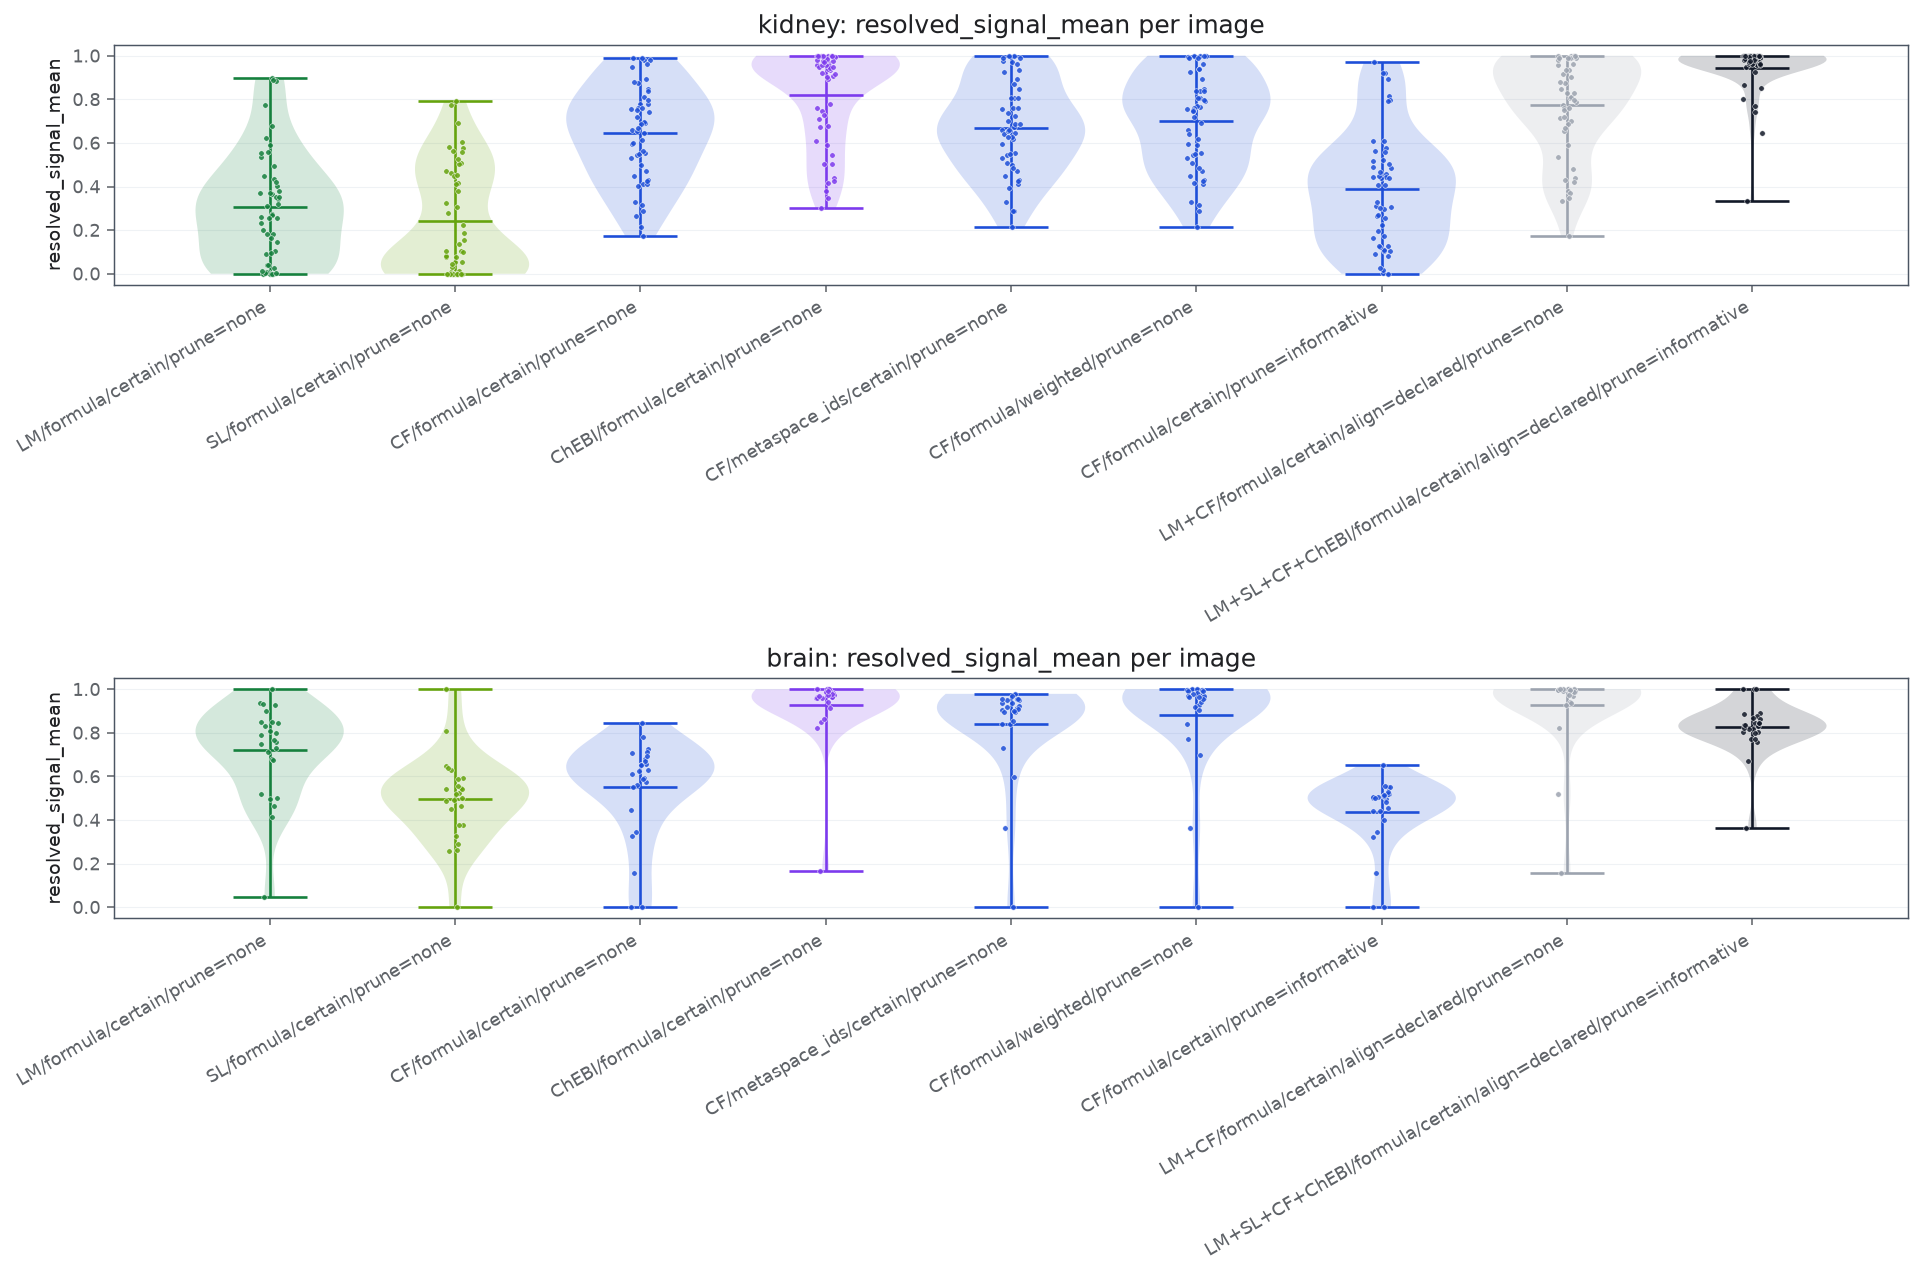

In [2]:
images = table("images.csv")
image_summary = table("image_summary.csv")
display(images.groupby("collection").agg(images=("dataset_id", "size"), pixels_median=("pixels", "median"),
                                          ions_median=("ions", "median")))
display(images[images.map_selected])

# --- what this figure shows -------------------------------------------------
METRIC = "resolved_signal_mean"     # resolved_signal_mean | effective_classes_mean
# ---------------------------------------------------------------------------
variants = list(dict.fromkeys(image_summary.variant_id))
short = {v: v.replace("/align=none", "").replace("/adduct=0", "").replace("/all_ancestors", "") for v in variants}
figure, axes = plt.subplots(len(COLLECTIONS), 1, figsize=(14, 4.6 * len(COLLECTIONS)), squeeze=False)
for axis, collection in zip(axes[:, 0], COLLECTIONS):
    rows = image_summary[image_summary.collection == collection].assign(group=lambda f: f.variant_id.map(short))
    plots.violin_groups(axis, rows, group="group", value=METRIC, order=[short[v] for v in variants],
                        colors={short[v]: plots.taxonomy_color(v.split("/")[0]) for v in variants}, theme=THEME)
    axis.set_title(f"{collection}: {METRIC} per image")
plt.tight_layout()

### Remarks

- Lipid taxonomies explain little of the kidney signal (median resolved share: LIPID MAPS 0.27, SwissLipids 0.12) but most of the brain signal (0.77, 0.52); ClassyFire 0.66 / 0.62, ChEBI 0.94 / 0.97, LM+CF 0.82 / 0.99.
- Informative pruning lowers ClassyFire's resolved share to 0.41 (kidney) / 0.50 (brain): many ions are attached only to classes removed as too general or too small.
- Kidney images `2026-04-21_18h07m29s` and `2026-04-21_18h16m54s` contain byte-identical ion images (duplicate upload); every per-image statistic counts this image twice.

### Notes

## Class maps on representative images

### Methodology

#### Theoretical

For one image, variant and hierarchy level, the maps show (i) the resolved signal $r_p$, (ii) the effective class count, (iii) the dominant class per pixel and (iv) the abundance $s_{pc}$ of the most abundant classes of that level. Spatially coherent dominant-class regions that follow tissue morphology indicate that class labels at that level carry anatomical information; salt-and-pepper patterns indicate that the level mixes signals that do not co-localize.

#### Implementation

Arrays are read from the stored `.npz` maps (`map_index.csv`): per taxonomy and depth up to `max_map_depth`, the abundances of the 8 classes with highest mean abundance, the dominant class over *all* classes of that level, and its share. Pixels without annotated signal are blank.

#### Figure descriptions

*Figure 2.* Top row: resolved signal $r_p$ (colour 0–1), effective number of classes, dominant class of the selected level (categorical colours assigned to the classes present, in order of pixel frequency; legend = class names). Bottom row: abundance $s_{pc}$ of the four most abundant classes of the level, each on its own colour scale (share of annotated signal). $x$/$y$ are pixel coordinates.

collection  dataset_id          
brain       2023-08-12_12h11m58s    9
            2025-12-19_21h52m37s    9
            2026-03-13_19h13m14s    9
kidney      2024-05-23_14h25m01s    9
            2026-04-21_18h07m29s    9
            2026-04-21_18h16m54s    9
dtype: int64
LM/formula/certain/all_ancestors/align=none/adduct=0/prune=none | levels: ['LIPID_MAPS_d0', 'LIPID_MAPS_d1', 'LIPID_MAPS_d2', 'LIPID_MAPS_d3']


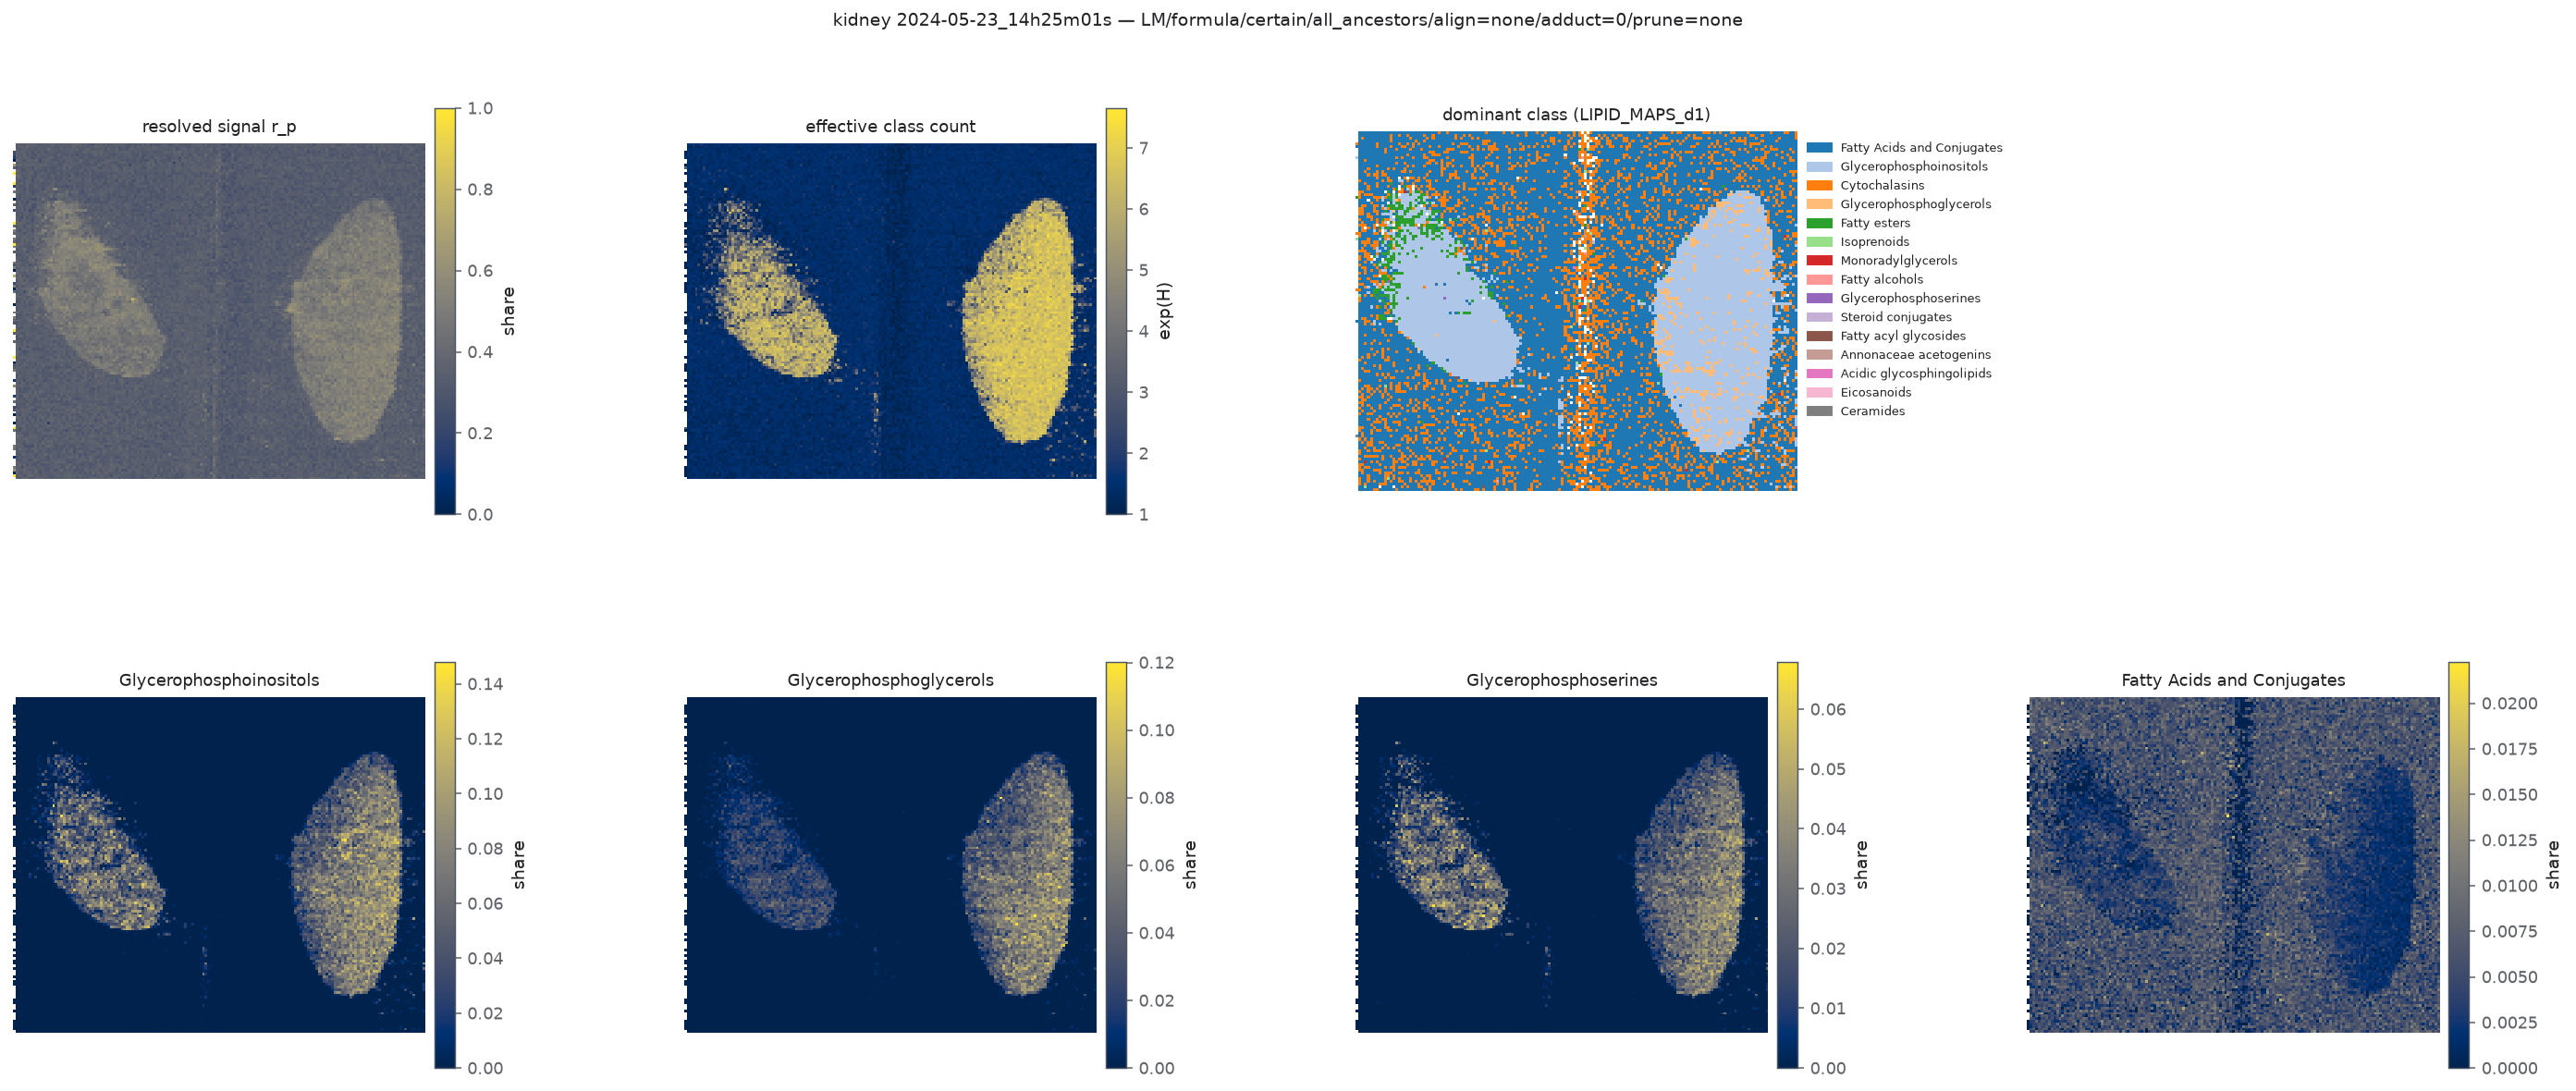

In [3]:
map_index = table("map_index.csv")
print(map_index.groupby(["collection", "dataset_id"]).size())

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
DATASET = None            # None = first map-selected image of the collection
VARIANT_INDEX = 0         # index into focus_variants (see map_index.csv)
LEVEL = "LIPID_MAPS_d1"   # <taxonomy>_d<depth>; LIPID_MAPS_d0 = categories, _d1 = main classes
TOP = 4
# ---------------------------------------------------------------------------
rows = map_index[(map_index.collection == COLLECTION) & (map_index.variant_index == VARIANT_INDEX)]
row = rows.iloc[0] if DATASET is None else rows[rows.dataset_id == DATASET].iloc[0]
with np.load(precompute.result_path(SETTINGS, ANALYSIS, row.file)) as payload:
    maps = {key: payload[key] for key in payload.files}
print(row.variant_id, "| levels:", sorted({k.split("__")[0] for k in maps if "__" in k}))
coordinates, mask = maps["coordinates"], maps["mask"]
figure, axes = plt.subplots(2, max(3, TOP), figsize=(5 * max(3, TOP), 9))
plots.continuous_map(axes[0, 0], plots.image_from_pixels(coordinates, mask, maps["resolved"].astype(float)),
                     title="resolved signal r_p", colorbar_label="share", vmin=0, vmax=1, theme=THEME)
plots.continuous_map(axes[0, 1], plots.image_from_pixels(coordinates, mask, maps["effective"].astype(float)),
                     title="effective class count", colorbar_label="exp(H)", theme=THEME)
if f"{LEVEL}__dominant" in maps:
    labels = [name or class_id.split(":")[-1] for class_id, name in zip(maps[f"{LEVEL}__all_classes"], maps[f"{LEVEL}__all_names"])]
    plots.categorical_map(axes[0, 2], plots.image_from_pixels(coordinates, mask, maps[f"{LEVEL}__dominant"].astype(float)),
                          labels, title=f"dominant class ({LEVEL})", theme=THEME)
    for column in range(min(TOP, len(maps[f"{LEVEL}__classes"]))):
        plots.continuous_map(axes[1, column], plots.image_from_pixels(coordinates, mask, maps[f"{LEVEL}__abundance"][column].astype(float)),
                             title=str(maps[f"{LEVEL}__names"][column])[:40], colorbar_label="share", theme=THEME)
for axis in axes.ravel():
    if not axis.has_data() and not axis.images:
        axis.set_axis_off()
figure.suptitle(f"{COLLECTION} {row.dataset_id} — {row.variant_id}", fontsize=10)
plt.tight_layout()

### Remarks

- In the representative kidney image both tissue sections are dominated by glycerophosphoinositols, with rims where glycerophosphoglycerols (right section) or fatty esters (left section) dominate; the off-tissue background is dominated by fatty acids and by *cytochalasins* (a polyketide class), which indicates background/matrix ions entering class maps as classes of their own, partly with implausible class assignments.

### Notes

## Class composition across images

### Methodology

#### Theoretical

The image-level class composition $\bar s_{ic} = \frac{1}{|P_i|}\sum_{p\in P_i} s_{pc}$ compares images. Classes with stable composition across images are robust supervision targets; classes present in only some images make class labels image-dependent (batch or tissue-region effects).

#### Implementation

`class_composition.csv` contains $\bar s_{ic}$ for all images, focus variants and classes up to `max_map_depth` with non-zero abundance. The heatmap is restricted to the selected taxonomy level and its most abundant classes.

#### Figure descriptions

*Figure 3.* Left: heatmap of $\bar s_{ic}$ (colour) with images as rows and classes of the selected level as columns. Right: violins of $\bar s_{ic}$ over images per class; each point is one image. Wide violins indicate image-dependent class composition.

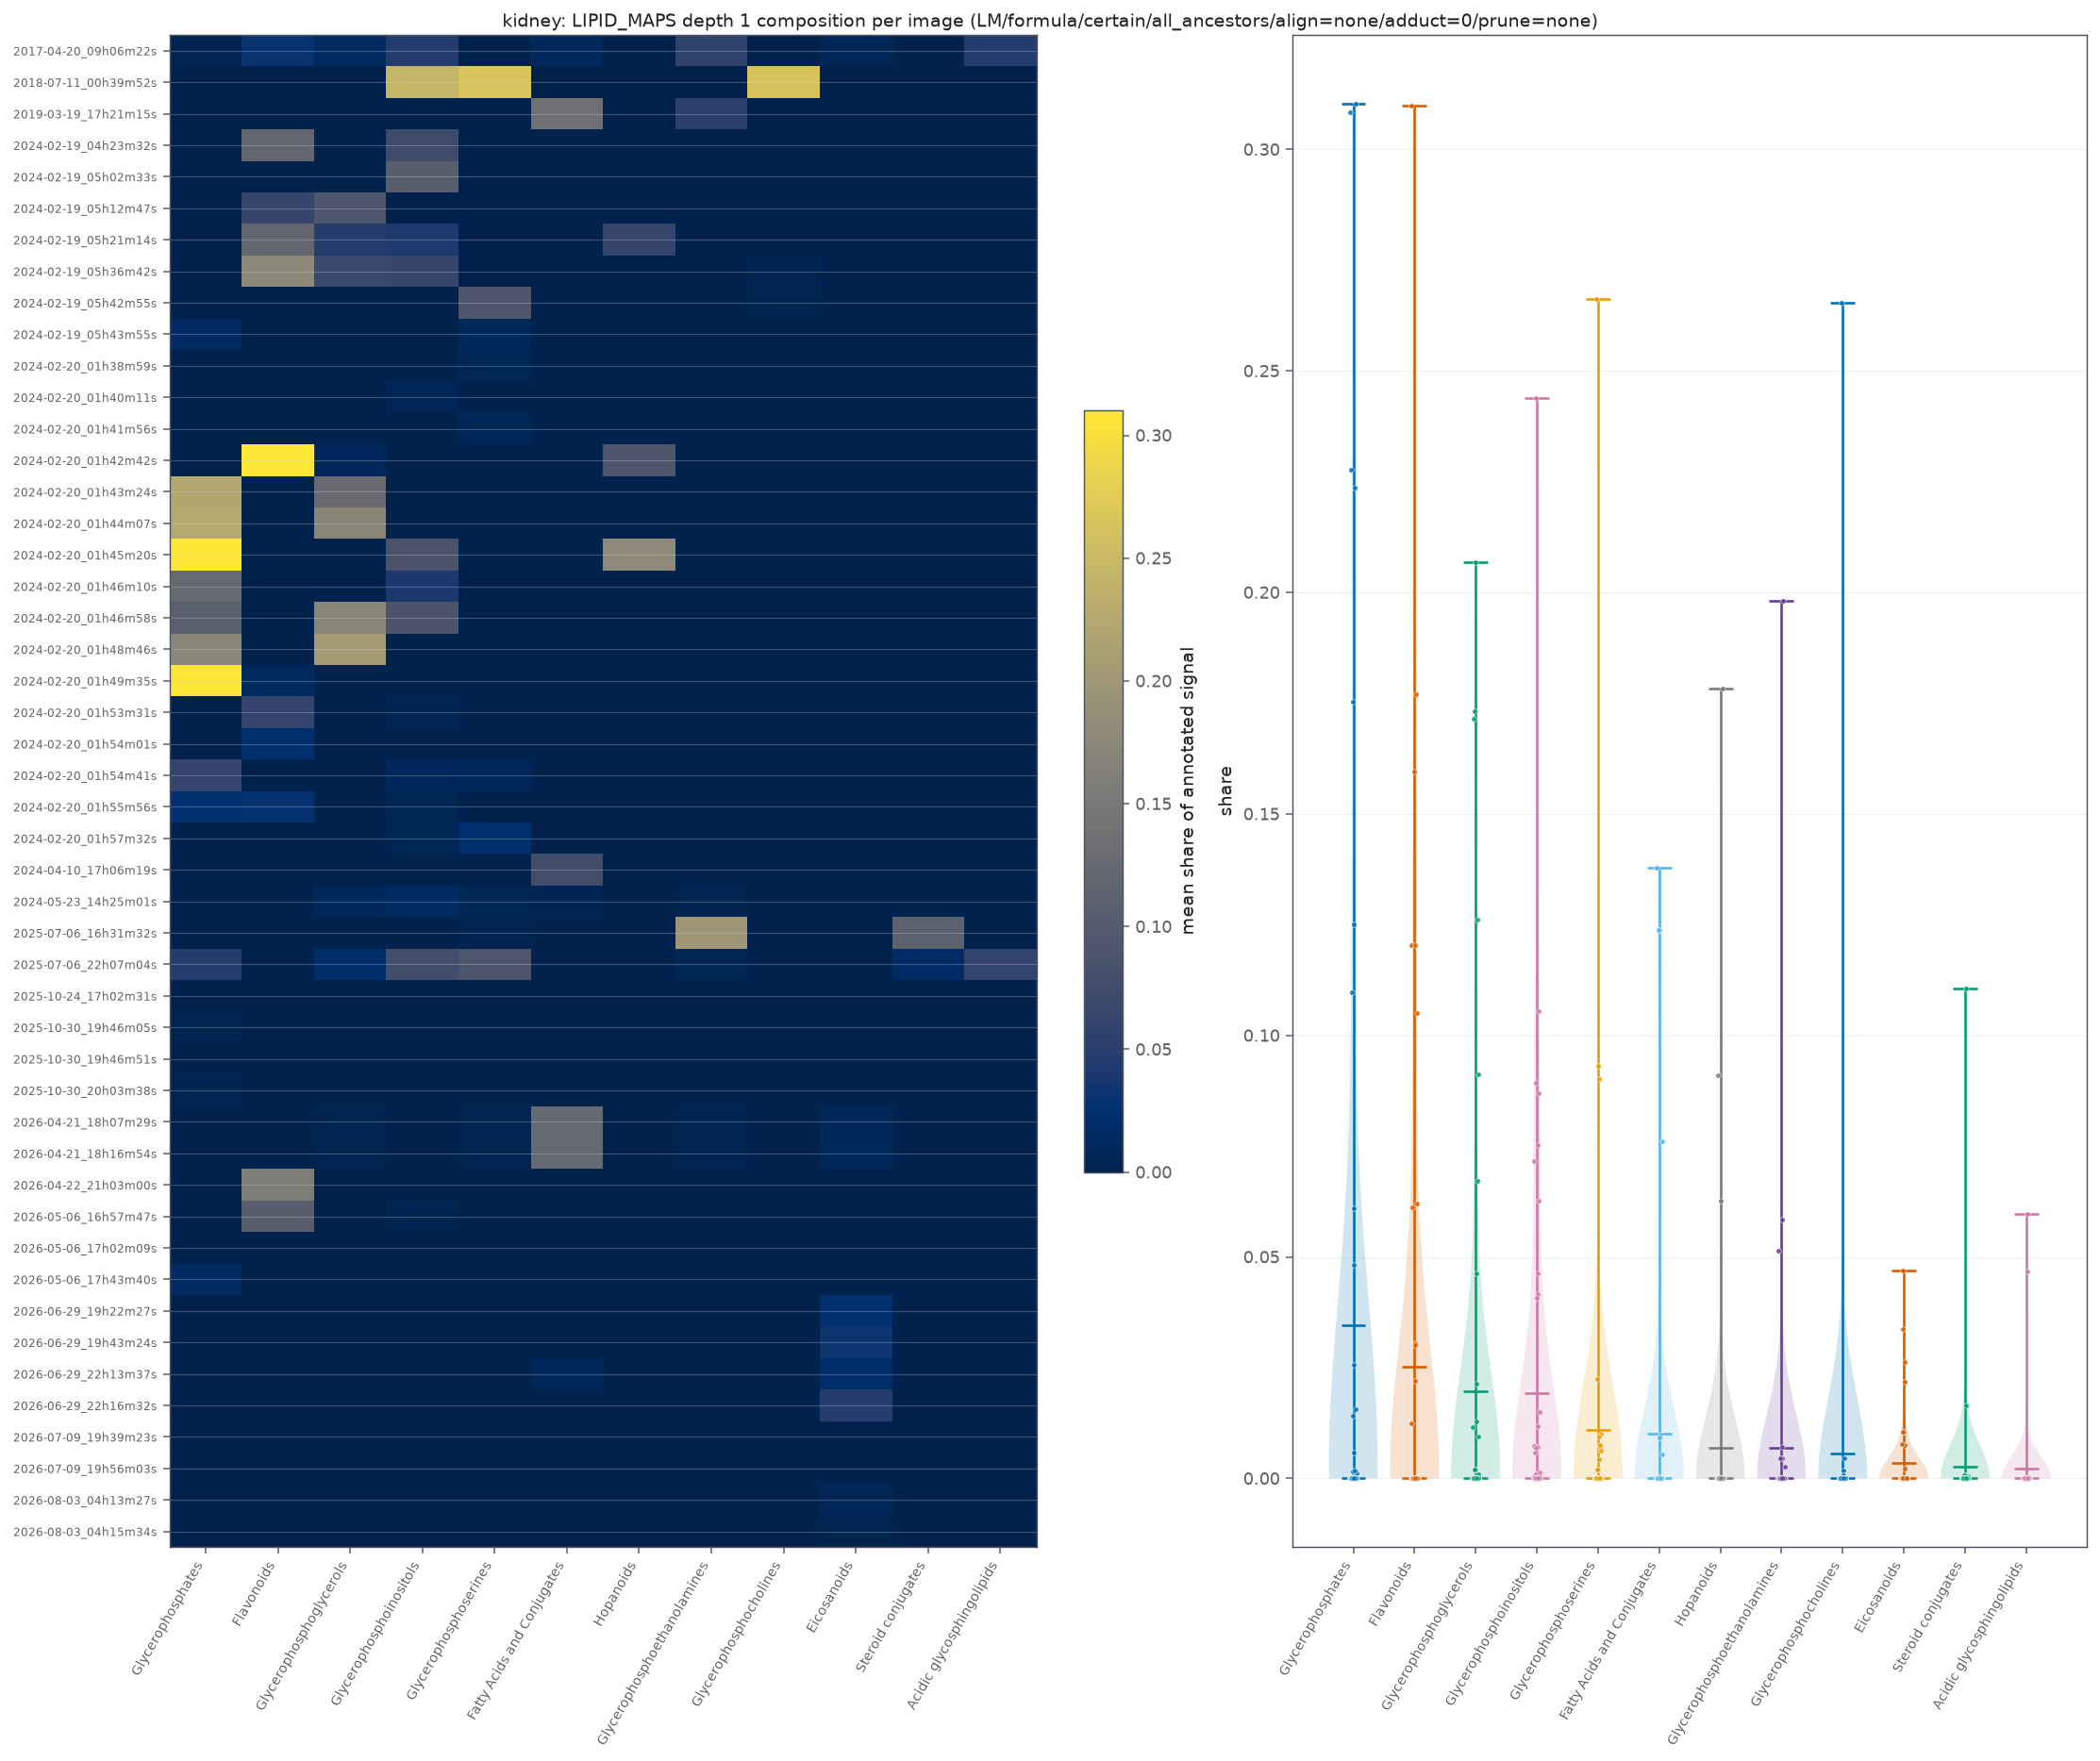

In [4]:
composition = table("class_composition.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
VARIANT = "LM/formula/certain/all_ancestors/align=none/adduct=0/prune=none"
TAXONOMY, DEPTH = "LIPID_MAPS", 1
TOP = 12
# ---------------------------------------------------------------------------
rows = composition[(composition.collection == COLLECTION) & (composition.variant_id == VARIANT)
                   & (composition.taxonomy == TAXONOMY) & (composition.depth == DEPTH)]
pivot = rows.pivot_table(index="dataset_id", columns="name", values="mean_abundance", fill_value=0.0)
pivot = pivot[pivot.mean().nlargest(TOP).index]
figure, axes = plt.subplots(1, 2, figsize=(16, 0.22 * len(pivot) + 3), gridspec_kw={"width_ratios": [1.2, 1]})
handle = axes[0].imshow(pivot, aspect="auto", cmap=THEME.image_colormap)
axes[0].set_xticks(range(pivot.shape[1]), [c[:28] for c in pivot.columns], rotation=60, ha="right", fontsize=7)
axes[0].set_yticks(range(pivot.shape[0]), pivot.index, fontsize=6)
plt.colorbar(handle, ax=axes[0], fraction=0.04, label="mean share of annotated signal")
long = pivot.reset_index().melt(id_vars="dataset_id", var_name="class", value_name="share")
plots.violin_groups(axes[1], long, group="class", value="share", order=list(pivot.columns), theme=THEME)
axes[1].set_xticklabels([c[:28] for c in pivot.columns], rotation=60, ha="right", fontsize=7)
figure.suptitle(f"{COLLECTION}: {TAXONOMY} depth {DEPTH} composition per image ({VARIANT})", fontsize=10)
plt.tight_layout()

### Remarks

- Kidney class composition is strongly image dependent: only 26 of 48 images with LIPID MAPS classes have any main class above 5 % of annotated signal, and the dominant class changes between acquisition batches (e.g. glycerophosphates in the 2024-02-20 series, flavonoids in a few images). Brain is more homogeneous (23 of 25).

### Notes

## Activated label subgraph of a single pixel

### Methodology

#### Theoretical

The final relation between a spectrum and the chemical graph is the set of classes with non-zero abundance in a pixel together with their hierarchy: the classes that a class head would be asked to predict and through which a graph network would couple their classifiers. Drawing this activated subgraph for the strongest pixel of an image makes the per-pixel label structure explicit.

#### Implementation

`pixel_footprints.csv` stores, for every map-selected image and focus variant, the pixel with the largest annotated signal and all classes with positive abundance, their depth, taxonomy and retained `is_a` parents in the variant. Node size encodes abundance.

#### Figure descriptions

*Figure 4.* Layered drawing of the activated classes of one pixel (no ion nodes): rows by class depth with roots on top; colour = taxonomy; marker size grows with the class abundance $s_{pc}$ in that pixel (scaled ×100 for display); edges are `is_a` relations between activated classes.

,taxonomy,depth,name,abundance
2421,ChEBI,3,heteroatomic molecular entity,0.415
2365,ChEBI,4,pnictogen molecular entity,0.383
2362,ChEBI,4,oxoacid derivative,0.358
2343,ChEBI,5,oxygen molecular entity,0.434
2418,ChEBI,5,organochalcogen compound,0.431
2419,ChEBI,6,organooxygen compound,0.427
2311,ChEBI,6,lipid,0.348
2400,ChEBI,7,ester,0.358
2464,ClassyFire,2,Lipids and lipid-like molecules,0.355
2472,ClassyFire,3,Glycerophospholipids,0.176


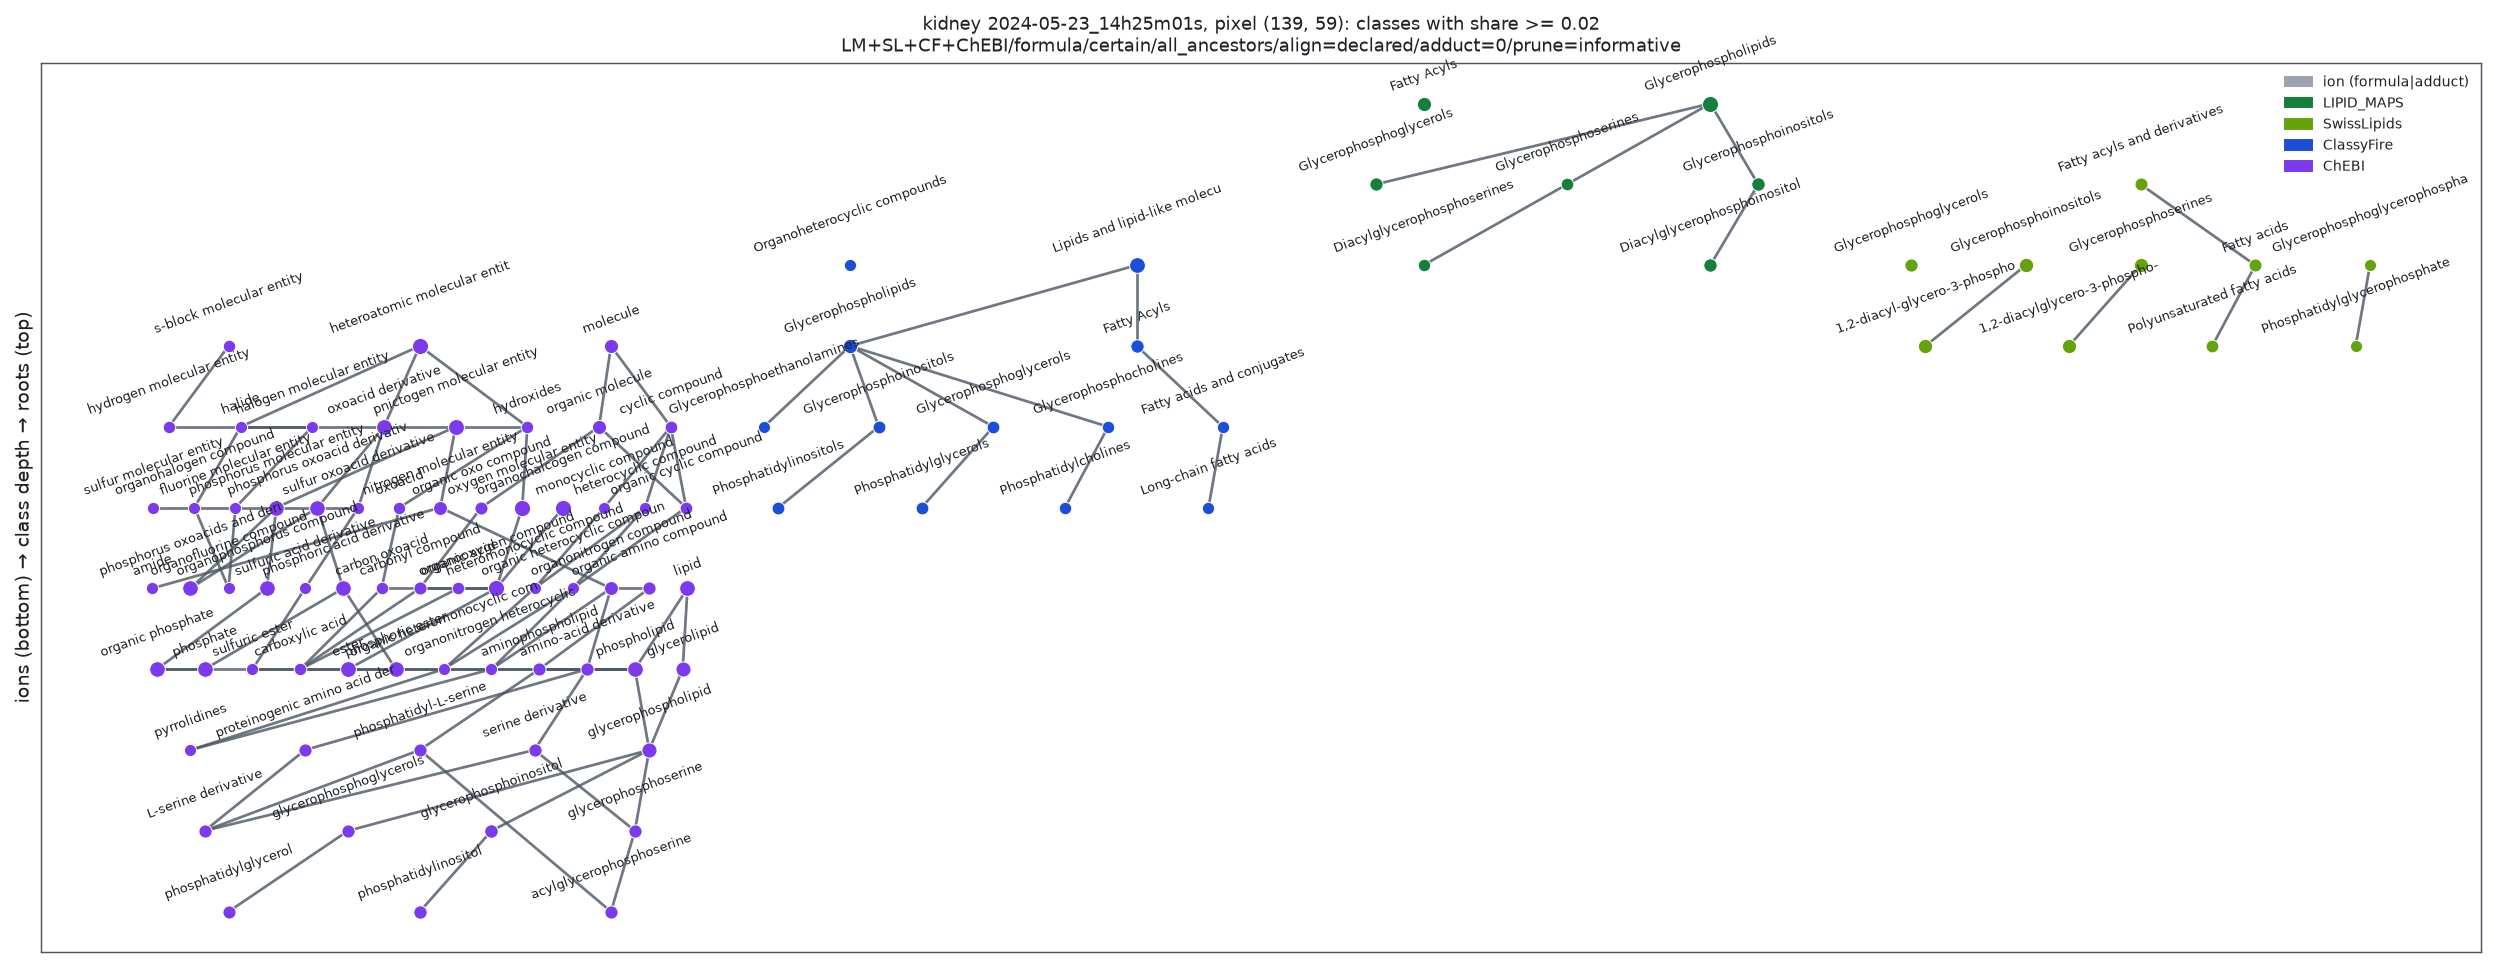

In [5]:
footprints = table("pixel_footprints.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
DATASET = None
VARIANT = "LM+SL+CF+ChEBI/formula/certain/all_ancestors/align=declared/adduct=0/prune=informative"
MIN_ABUNDANCE = 0.02
# ---------------------------------------------------------------------------
rows = footprints[(footprints.collection == COLLECTION) & (footprints.variant_id == VARIANT)]
dataset = rows.dataset_id.iloc[0] if DATASET is None else DATASET
rows = rows[(rows.dataset_id == dataset) & (rows.abundance >= MIN_ABUNDANCE)]
footprint_nodes = rows.rename(columns={"class_id": "node_id"}).assign(node_type="class", support=lambda f: 100 * f.abundance)
footprint_edges = pd.DataFrame([(child, parent, "is_a") for child, parents in zip(rows.class_id, rows.parents.fillna(""))
                                for parent in parents.split(";") if parent and parent in set(rows.class_id)],
                               columns=["source", "target", "relation"])
figure, axis = plt.subplots(figsize=(18, 7))
plots.draw_label_graph(axis, footprint_nodes, footprint_edges, theme=THEME)
axis.set_title(f"{COLLECTION} {dataset}, pixel ({rows.x.iloc[0]}, {rows.y.iloc[0]}): classes with share >= {MIN_ABUNDANCE}\n{VARIANT}", fontsize=9)
plt.tight_layout()
display(rows.sort_values("abundance", ascending=False).groupby("taxonomy").head(8)
        .sort_values(["taxonomy", "depth"])[["taxonomy", "depth", "name", "abundance"]].round(3))

### Remarks

- The activated subgraph of a single pixel contains a few lipid classes per lipid taxonomy but dozens of ChEBI classes, most of them structural generalities (*organic molecular entity*, *oxoacid derivative*); ChEBI therefore dominates any per-pixel label vector it is part of.

### Notes

## Results / Summary

### LLM

**Observed.** Class maps follow tissue outlines: in the representative kidney image glycerophosphoinositols dominate both sections, other phospholipid classes dominate section rims and their abundances vary within sections, while background pixels are dominated by fatty acids and implausible classes (cytochalasins). Whether within-section patterns correspond to anatomical regions is not verified here (no histological reference). Lipid taxonomies explain 27 % (kidney) and 77 % (brain) of annotated signal per image (medians); combined LM+CF graphs explain 82 % / 99 %. Class composition varies strongly between kidney acquisition batches.

**Interpretation.** Class-level labels carry spatial information and are therefore plausible auxiliary targets, but in kidney most annotated signal is non-lipid, so a lipid-only class head would supervise a minority of the signal; ClassyFire (or LM+CF) is needed for coverage. Batch-dependent composition means that class supervision may also encode acquisition batch; group-wise validation by image or batch is required.

**Caveats.** Maps use annotated signal only; background/matrix signal forms its own class; one kidney image is duplicated in the workspace.

### Person